In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataframe = pd.read_csv("Zomato-data.csv")

In [3]:
dataframe

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining


In [4]:
def handleRate(value):
    value=str(value).split('/')
    value=value[0]
    return float(value)

In [5]:
dataframe['rate']=dataframe['rate'].apply(handleRate)

In [6]:
dataframe

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3,0,100,Dining
144,New Indraprasta,No,No,3.3,0,150,Dining
145,Anna Kuteera,Yes,No,4.0,771,450,Dining
146,Darbar,No,No,3.0,98,800,Dining


In [7]:
dataframe['name']

0                      Jalsa
1             Spice Elephant
2            San Churro Cafe
3      Addhuri Udupi Bhojana
4              Grand Village
               ...          
143         Melting Melodies
144          New Indraprasta
145             Anna Kuteera
146                   Darbar
147            Vijayalakshmi
Name: name, Length: 148, dtype: object

In [8]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    object 
 1   online_order                 148 non-null    object 
 2   book_table                   148 non-null    object 
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


In [9]:
dataframe.shape

(148, 7)

In [10]:
# checking for missing/null values in each column
dataframe.isnull().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

Text(0.5, 0, 'Type of Restaurant')

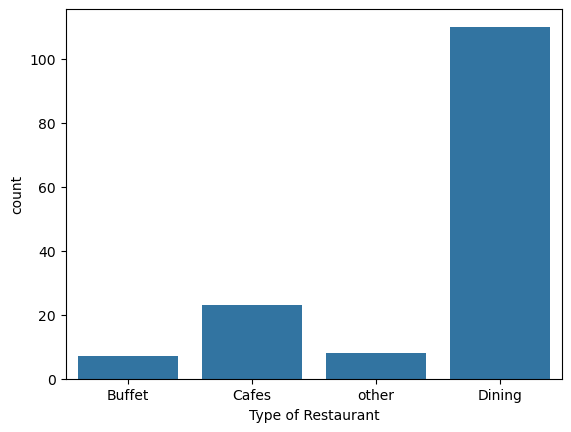

In [11]:
sns.countplot(x=dataframe['listed_in(type)'])
plt.xlabel("Type of Restaurant")

In [12]:
grouped_data= dataframe.groupby('listed_in(type)')["votes"].sum()
grouped_data

listed_in(type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: votes, dtype: int64

In [13]:
result = pd.DataFrame({'votes': grouped_data})
result

,votes
listed_in(type),
Buffet,3028
Cafes,6434
Dining,20363
other,9367


Text(0, 0.5, 'Votes')

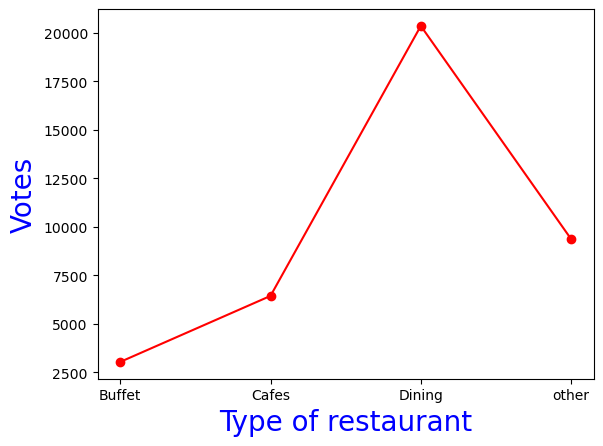

In [14]:
plt.plot(result, c='red',marker="o")
plt.xlabel("Type of restaurant",c="blue",size=20)
plt.ylabel('Votes',c='blue',size=20)

In [15]:
max_votes = dataframe['votes'].max()
max_votes

4884

In [16]:
# Find the maximum votes
max_votes = dataframe['votes'].max()

# Find the second highest votes
second_highest_votes = dataframe[dataframe['votes'] < max_votes]['votes'].max()

second_highest_votes

4401

In [17]:
restaurant_with_max_votes = dataframe.loc[dataframe['votes'] == max_votes, 'name']

print('Restaurant(s) with the maximum votes:')
print(restaurant_with_max_votes)

Restaurant(s) with the maximum votes:
38    Empire Restaurant
Name: name, dtype: object


In [18]:
# Get restaurant(s) with the second highest votes:
restaurant_with_second_highest_votes = dataframe.loc[dataframe['votes'] == second_highest_votes, 'name']

print('Restaurant(s) with the second highest votes:')
print(restaurant_with_second_highest_votes)

Restaurant(s) with the second highest votes:
86    Meghana Foods
Name: name, dtype: object


<Axes: xlabel='online_order', ylabel='count'>

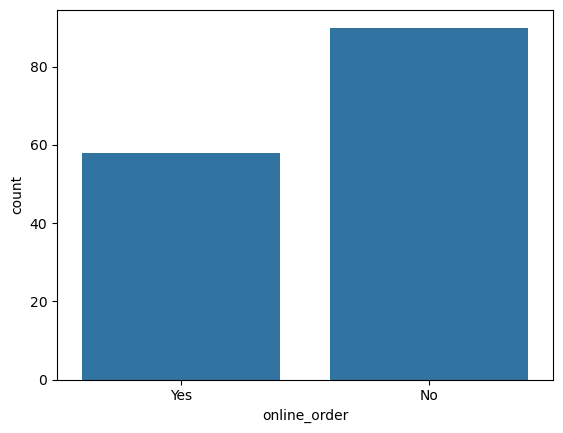

In [19]:
sns.countplot(x=dataframe['online_order'])

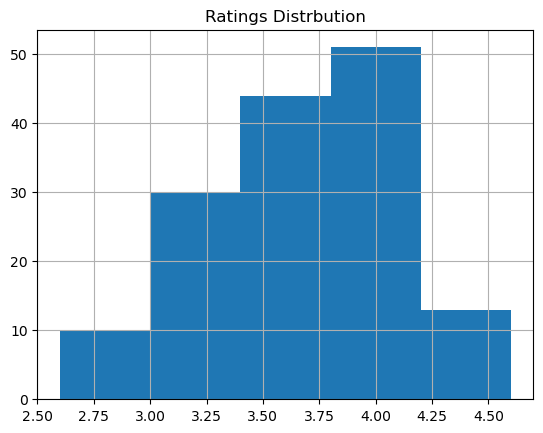

In [22]:
plt.hist(dataframe['rate'],bins=5)
plt.title("Ratings Distrbution")
plt.grid()
plt.show()

<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

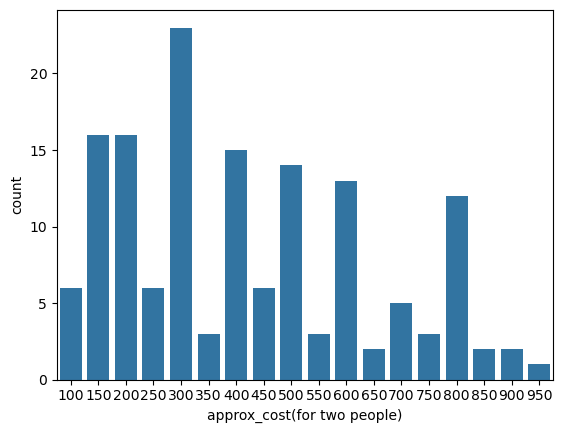

In [25]:
couple_date=dataframe['approx_cost(for two people)']
sns.countplot(x=couple_date)

C:\Users\disha\AppData\Local\Temp\ipykernel_15824\4217655009.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='online_order',y='rate',data=dataframe,palette='Set2')


<Axes: xlabel='online_order', ylabel='rate'>

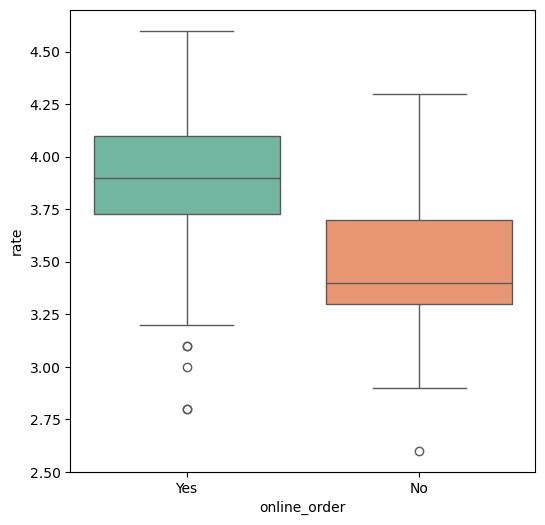

In [29]:
plt.figure(figsize=(6,6))
sns.boxplot(x='online_order',y='rate',data=dataframe,palette='Set2')

In [30]:
pivot_table= dataframe.pivot_table(index='listed_in(type)', columns='online_order', aggfunc='size',fill_value=0)
pivot_table

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6


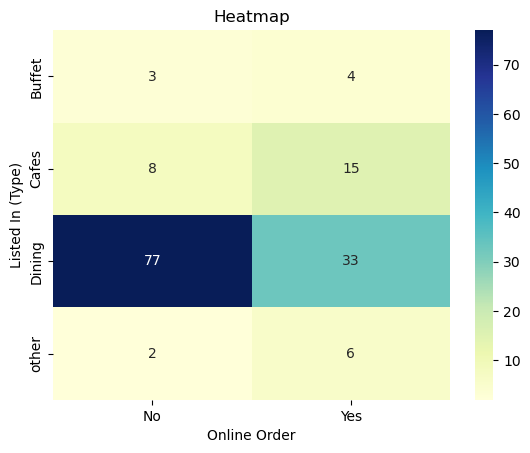

In [31]:
sns.heatmap(pivot_table, annot=True, cmap='YlGnBu', fmt='d')
plt.title('Heatmap')
plt.xlabel('Online Order')
plt.ylabel('Listed In (Type)')
plt.show()